In [7]:
import os
import sys
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fix Windows + Anaconda PySpark worker connection issue
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, udf, sha2, count, when
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, BinaryType, ArrayType, FloatType
from pyspark.ml.feature import StringIndexer, OneHotEncoder

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Lock random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:
spark = SparkSession.builder \
    .appName("CNN_Distributed_Image_Recognition") \
    .master("local[2]") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("Spark Session connected and active!")


Spark Session connected and active!


In [11]:
import pandas as pd

# 1. Unpickle the CIFAR-100 file on your Desktop
dataset_path = r"C:\Users\User\Desktop\cifar_100_python_train"
with open(dataset_path, "rb") as f:
    cifar_dict = pickle.load(f, encoding="bytes")

raw_images = cifar_dict[b"data"]
coarse_labels = cifar_dict[b"coarse_labels"]

# 2. Filter to 5 distinct classes (5 x 2,500 = 12,500 exact records)
selected_classes = {
    0: "aquatic_mammals",
    1: "fish",
    4: "fruit_and_vegetables",
    11: "large_omnivores_and_herbivores",
    18: "vehicles_1"
}

records = []
for idx, (img_flat, label_id) in enumerate(zip(raw_images, coarse_labels)):
    if label_id in selected_classes:
        img_rgb = img_flat.reshape(3, 32, 32).transpose(1, 2, 0).astype(np.uint8)
        records.append({
            "file_path": f"cifar100_train_{idx}.png",
            "height": 32,
            "width": 32,
            "channels": 3,
            "raw_hex": img_rgb.tobytes().hex(),
            "class_label": selected_classes[label_id]
        })

# 3. Save to CSV so Spark reads it natively in Java with zero extra libraries
csv_path = r"C:\Users\User\Desktop\cifar100_subset.csv"
pd.DataFrame(records).to_csv(csv_path, index=False)

# 4. Load natively into PySpark DataFrame
eda_df = spark.read.csv(csv_path, header=True, inferSchema=True).repartition(4).cache()
print(f"Successfully loaded {eda_df.count()} records into PySpark!")


Successfully loaded 12500 records into PySpark!


In [13]:
from pyspark.sql.functions import col, sha2, count, when, length

# 1. Print Columns & Schema Data Types
print("1. DataFrame Columns:", eda_df.columns)
print("\n2. Schema & Data Types:")
eda_df.printSchema()

# 2. Missing Value Check
print("\n3. Missing Values Count:")
eda_df.select([
    count(when(col(c).isNull(), c)).alias(c) for c in eda_df.columns
]).show()

no_nulls_df = eda_df.dropna()

# 3. Duplicate Image Detection via SHA-256 Hashing on 'raw_hex'
hashed_df = no_nulls_df.withColumn("image_hash", sha2(col("raw_hex"), 256))
dedup_df = hashed_df.dropDuplicates(["image_hash"]).drop("image_hash")
print(f"4. Duplicates Removed: {no_nulls_df.count() - dedup_df.count()} | Unique Rows: {dedup_df.count()}")

# 4. Statistical Summary & Dimension Quantile Check
print("\n5. Image Dimension Summary Statistics:")
dedup_df.select("height", "width", "channels").summary().show()

height_q = dedup_df.approxQuantile("height", [0.50, 0.90, 0.99], 0.01)
width_q = dedup_df.approxQuantile("width", [0.50, 0.90, 0.99], 0.01)
print(f"Height Percentiles (50th, 90th, 99th): {height_q}")
print(f"Width Percentiles  (50th, 90th, 99th): {width_q}")

# Filter out non-RGB, wrong dimensions, or incomplete hex strings (32*32*3*2 = 6144 hex chars)
clean_df = dedup_df.filter(
    (col("channels") == 3) & 
    (col("height") == 32) & 
    (col("width") == 32) & 
    (length(col("raw_hex")) == 6144)
)

# 5. Pixel Brightness Statistics (computed safely without Windows UDF socket crashes)
sample_hex = [r["raw_hex"] for r in clean_df.select("raw_hex").collect()]
all_pixels = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in sample_hex])
print("\n6. Pixel Intensity Statistics (0 to 255 scale):")
print(f"Min: {all_pixels.min()} | Mean: {all_pixels.mean():.2f} | StdDev: {all_pixels.std():.2f} | Max: {all_pixels.max()}")

# 6. Class Distribution Check (1:1 Balance)
print("\n7. Class Distribution:")
class_counts_df = clean_df.groupBy("class_label").count().orderBy("class_label")
class_counts_df.show()
print(f"Final Cleaned Total Rows: {clean_df.count()}")


1. DataFrame Columns: ['file_path', 'height', 'width', 'channels', 'raw_hex', 'class_label']

2. Schema & Data Types:
root
 |-- file_path: string (nullable = true)
 |-- height: integer (nullable = true)
 |-- width: integer (nullable = true)
 |-- channels: integer (nullable = true)
 |-- raw_hex: string (nullable = true)
 |-- class_label: string (nullable = true)


3. Missing Values Count:
+---------+------+-----+--------+-------+-----------+
|file_path|height|width|channels|raw_hex|class_label|
+---------+------+-----+--------+-------+-----------+
|        0|     0|    0|       0|      0|          0|
+---------+------+-----+--------+-------+-----------+

4. Duplicates Removed: 9 | Unique Rows: 12491

5. Image Dimension Summary Statistics:
+-------+------+-----+--------+
|summary|height|width|channels|
+-------+------+-----+--------+
|  count| 12491|12491|   12491|
|   mean|  32.0| 32.0|     3.0|
| stddev|   0.0|  0.0|     0.0|
|    min|    32|   32|       3|
|    25%|    32|   32|      

C:\Users\User\anaconda3\lib\site-packages\pyspark\sql\pandas\conversion.py:111: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  PyArrow >= 4.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


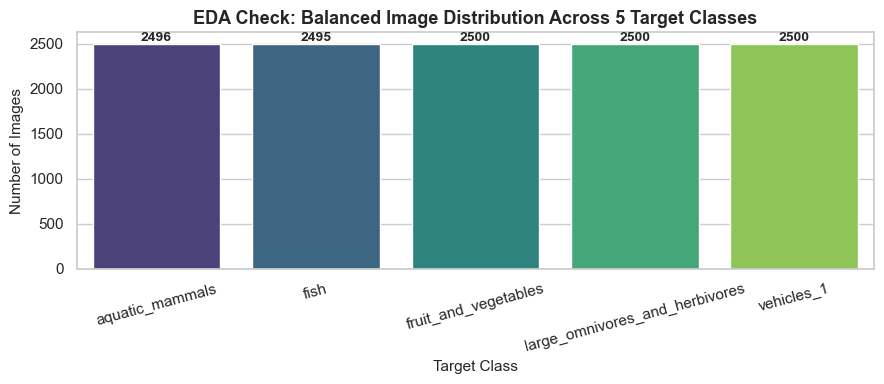

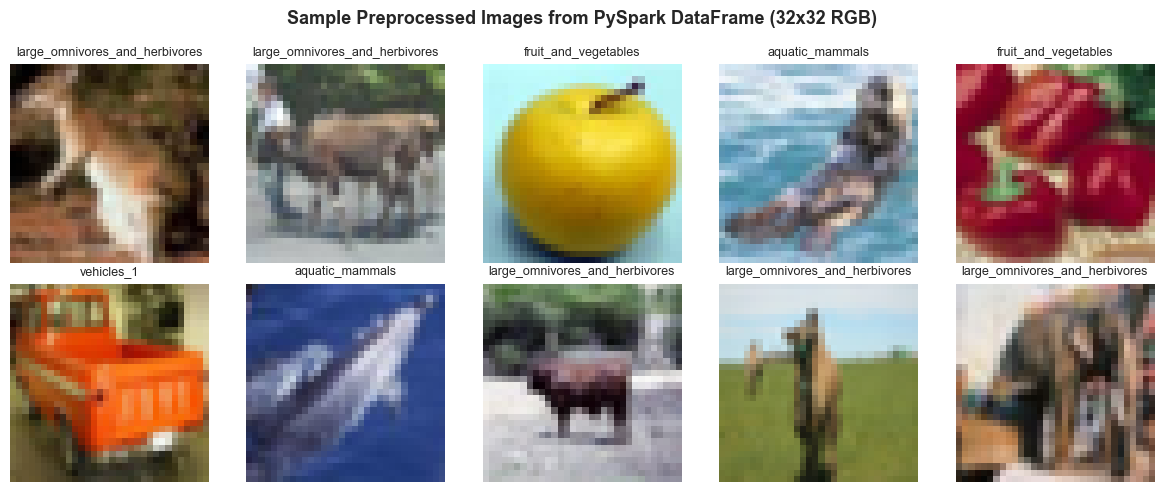

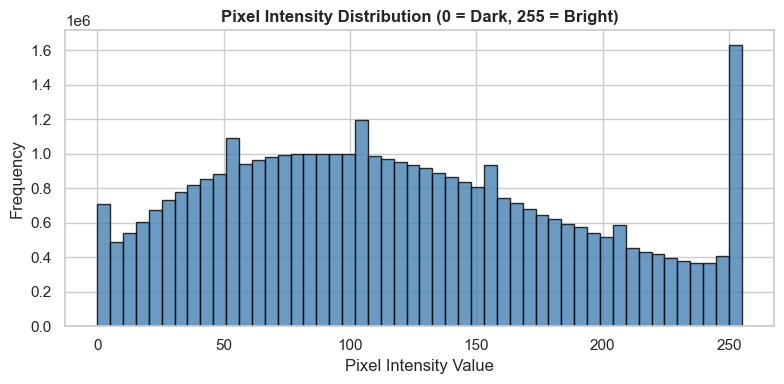

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set clean visual style
sns.set_theme(style="whitegrid")

# -------------------------------------------------------------------------
# CHART 1: Class Distribution Bar Chart (Proves 1:1 Balance)
# -------------------------------------------------------------------------
class_pd = class_counts_df.toPandas()

plt.figure(figsize=(9, 4))
ax = sns.barplot(data=class_pd, x="class_label", y="count", palette="viridis")
plt.title("EDA Check: Balanced Image Distribution Across 5 Target Classes", fontsize=13, fontweight="bold")
plt.xlabel("Target Class", fontsize=11)
plt.ylabel("Number of Images", fontsize=11)
plt.xticks(rotation=15)

# Add exact count labels on top of each bar
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("eda_class_balance.png", dpi=300)
plt.show()

# -------------------------------------------------------------------------
# CHART 2: Sample Image Grid (Visual Verification of Decoded Tensors)
# -------------------------------------------------------------------------
sample_rows = clean_df.limit(10).collect()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample Preprocessed Images from PySpark DataFrame (32x32 RGB)", fontsize=13, fontweight="bold")

for idx, ax in enumerate(axes.flat):
    img = np.frombuffer(bytes.fromhex(sample_rows[idx]["raw_hex"]), dtype=np.uint8).reshape(32, 32, 3)
    ax.imshow(img)
    ax.set_title(sample_rows[idx]["class_label"], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.savefig("eda_sample_images.png", dpi=300)
plt.show()

# -------------------------------------------------------------------------
# CHART 3: RGB Pixel Intensity Distribution Histogram
# -------------------------------------------------------------------------
plt.figure(figsize=(8, 4))
plt.hist(all_pixels.flatten(), bins=50, color="steelblue", edgecolor="black", alpha=0.8)
plt.title("Pixel Intensity Distribution (0 = Dark, 255 = Bright)", fontsize=12, fontweight="bold")
plt.xlabel("Pixel Intensity Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("eda_pixel_histogram.png", dpi=300)
plt.show()


--- AVERAGE RGB CHANNEL INTENSITY PER CLASS ---
                            Class     Red   Green    Blue
0                 aquatic_mammals  108.17  121.97  126.89
1                            fish  106.15  118.00  116.81
2            fruit_and_vegetables  153.26  125.63   92.22
3  large_omnivores_and_herbivores  123.23  118.57  101.92
4                      vehicles_1  126.95  123.87  118.38


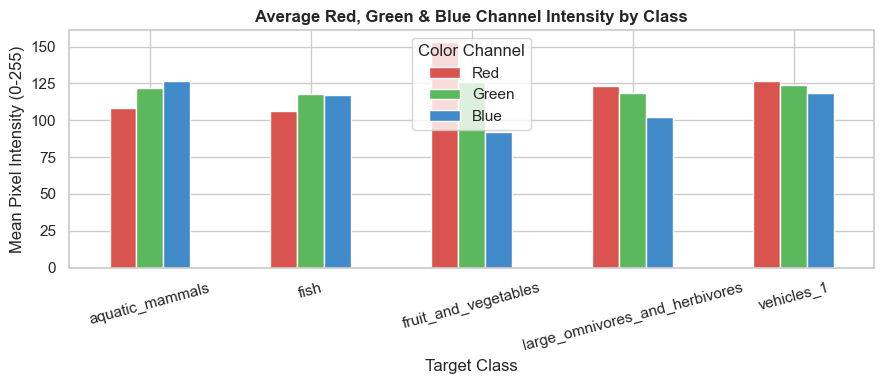

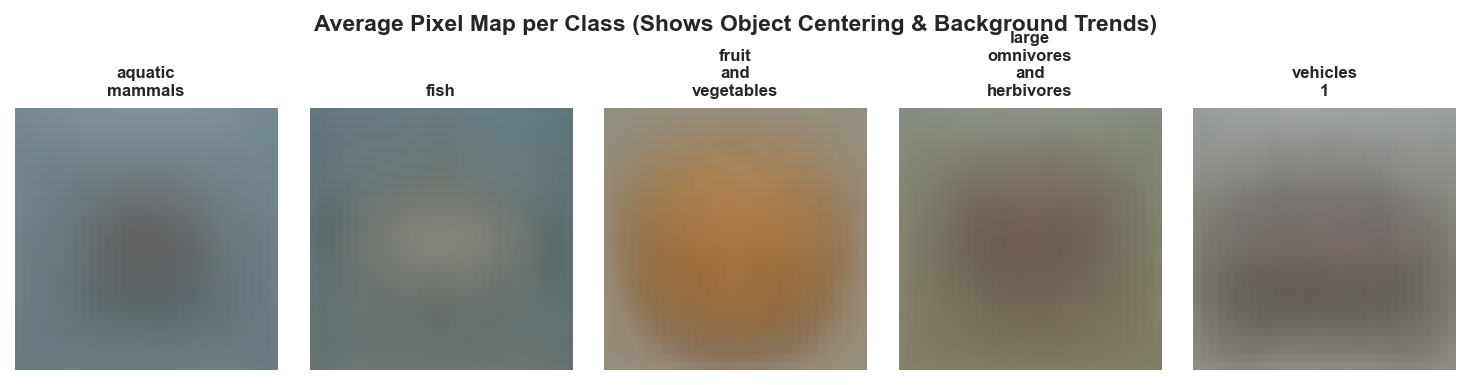

In [15]:
# Define the 5 target classes in alphabetical order
class_list = ["aquatic_mammals", "fish", "fruit_and_vegetables", "large_omnivores_and_herbivores", "vehicles_1"]
rgb_means = []

# Calculate average Red, Green, and Blue pixel brightness for each class
for cls in class_list:
    # Collect hex image strings for the current class
    cls_hex = [r["raw_hex"] for r in clean_df.filter(col("class_label") == cls).select("raw_hex").collect()]
    # Convert hex strings back into 32x32x3 RGB image arrays
    imgs = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8).reshape(32, 32, 3) for h in cls_hex])
    # Store the mean pixel intensity for Red (0), Green (1), and Blue (2) channels
    rgb_means.append({
        "Class": cls,
        "Red": round(float(imgs[:, :, :, 0].mean()), 2),
        "Green": round(float(imgs[:, :, :, 1].mean()), 2),
        "Blue": round(float(imgs[:, :, :, 2].mean()), 2)
    })

# Convert RGB averages into a table and print the results
rgb_df = pd.DataFrame(rgb_means)
print("--- AVERAGE RGB CHANNEL INTENSITY PER CLASS ---")
print(rgb_df)

# Plot a grouped bar chart comparing Red, Green, and Blue levels per class
rgb_df.set_index("Class").plot(kind="bar", figsize=(9, 4), color=["#d9534f", "#5cb85c", "#428bca"])
plt.title("Average Red, Green & Blue Channel Intensity by Class", fontsize=12, fontweight="bold")
plt.ylabel("Mean Pixel Intensity (0-255)")
plt.xlabel("Target Class")
plt.xticks(rotation=15)
plt.legend(title="Color Channel")
plt.tight_layout()
# Save the chart as a high-resolution PNG file
plt.savefig("eda_rgb_channels.png", dpi=300)
plt.show()

# Create a 1x5 grid to display the blended average image for each class
fig, axes = plt.subplots(1, 5, figsize=(10, 2.6), dpi=150)
fig.suptitle("Average Pixel Map per Class (Shows Object Centering & Background Trends)", fontsize=11, fontweight="bold")

# Blend all images in each class into one mean prototype image
for idx, cls in enumerate(class_list):
    cls_hex = [r["raw_hex"] for r in clean_df.filter(col("class_label") == cls).select("raw_hex").collect()]
    imgs = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8).reshape(32, 32, 3) for h in cls_hex])
    # Compute pixel-by-pixel average across all images in the class
    mean_img = imgs.mean(axis=0).astype(np.uint8)
    # Display the blended image without blurring the 32x32 pixels
    axes[idx].imshow(mean_img, interpolation="nearest")
    axes[idx].set_title(cls.replace("_", "\n"), fontsize=8, fontweight="bold")
    axes[idx].axis("off")

plt.tight_layout()
# Save the mean prototype grid to disk
plt.savefig("eda_mean_class_images.png", dpi=300, bbox_inches="tight")
plt.show()


In [16]:
# Feature Engineering & Stratified Split

# Convert text class labels into numeric indices (0.0 to 4.0)
indexer = StringIndexer(inputCol="class_label", outputCol="label_index", handleInvalid="skip")
indexer_model = indexer.fit(clean_df)
indexed_df = indexer_model.transform(clean_df)

# Convert numeric indices into binary One-Hot vectors for Softmax classification
encoder = OneHotEncoder(inputCol="label_index", outputCol="target_vector", dropLast=False)
encoded_df = encoder.fit(indexed_df).transform(indexed_df).cache()

# Enforce a Stratified 80/20 Train-Validation split using a locked seed
fractions = {float(i): 0.8 for i in range(5)}
train_df = encoded_df.sampleBy("label_index", fractions=fractions, seed=42)
# Isolate the remaining 20% of records as the unseen validation set
val_df = encoded_df.subtract(train_df)

print(f"Training Set Rows: {train_df.count()} | Validation Set Rows: {val_df.count()}")

# Decode hex strings into 4D NumPy tensors (N, 32, 32, 3) and scale pixels to [0.0, 1.0]
def spark_to_tensors(spark_df):
    # Collect hex features and one-hot target vectors from Spark partitions
    rows = spark_df.select("raw_hex", "target_vector").collect()
    # Reshape byte arrays into 32x32x3 grids and normalize pixel values from 0-255 to 0.0-1.0
    X = np.array(
        [np.frombuffer(bytes.fromhex(r["raw_hex"]), dtype=np.uint8) for r in rows],
        dtype=np.float32
    ).reshape(-1, 32, 32, 3) / 255.0
    # Extract one-hot label arrays
    y = np.array([r["target_vector"].toArray() for r in rows], dtype=np.float32)
    return X, y

# Build training and validation NumPy arrays
X_train, y_train = spark_to_tensors(train_df)
X_val, y_val = spark_to_tensors(val_df)
print(f"Tensor Shapes -> X_train: {X_train.shape}, X_val: {X_val.shape}")


Training Set Rows: 9948 | Validation Set Rows: 2543
Tensor Shapes -> X_train: (9948, 32, 32, 3), X_val: (2543, 32, 32, 3)


In [17]:
# Build & Train the 2D CNN Model

# Define a 3-block 2D Convolutional Neural Network architecture
def build_cnn_model(input_shape=(32, 32, 3), num_classes=5):
    model = models.Sequential(name="PySpark_CIFAR100_CNN")
    
    # Block 1: Extract low-level edges and lines using 32 filters (3x3 kernel)
    model.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu", input_shape=input_shape))
    # Drop entire 2D feature maps (20% rate) to prevent pixel memorization
    model.add(layers.SpatialDropout2D(0.2))
    # Shrink spatial dimensions by half (32x32 -> 16x16) to retain strongest features
    model.add(layers.MaxPooling2D((2, 2)))
    
    # Block 2: Combine edges into mid-level textures using 64 filters
    model.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu"))
    model.add(layers.SpatialDropout2D(0.2))
    # Shrink spatial dimensions by half (16x16 -> 8x8)
    model.add(layers.MaxPooling2D((2, 2)))
    
    # Block 3: Detect high-level object parts using 128 filters
    model.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu"))
    # Shrink spatial dimensions by half (8x8 -> 4x4)
    model.add(layers.MaxPooling2D((2, 2)))
    
    # Flatten 3D feature cubes (4x4x128) into a 1D vector before dense layers
    model.add(layers.Flatten())
    # Learn non-linear feature combinations in a 256-neuron dense layer
    model.add(layers.Dense(256, activation="relu"))
    # Randomly turn off 50% of dense neurons during training to stop overfitting
    model.add(layers.Dropout(0.5))
    # Output class probability percentages across all 5 categories using Softmax
    model.add(layers.Dense(num_classes, activation="softmax"))
    
    # Compile the CNN with Adam optimizer and Categorical Cross-Entropy loss
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Instantiate the model and print the layer-by-layer summary
cnn_model = build_cnn_model()
cnn_model.summary()

# Configure EarlyStopping and automatic best-model checkpointing
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_cnn_model.keras", monitor="val_accuracy", save_best_only=True)
]

# Train the CNN across 20 epochs with a batch size of 32
history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks
)


C:\Users\User\anaconda3\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "PySpark_CIFAR100_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout2d (SpatialDropout2D) │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout2d_1                  │ (None, 16, 16, 64)          │               0 │
│ (SpatialDropout2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           1,285 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 619,077 (2.36 MB)

 Trainable params: 619,077 (2.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.3581 - loss: 1.4388 - val_accuracy: 0.5592 - val_loss: 1.1210
Epoch 2/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.5221 - loss: 1.1638 - val_accuracy: 0.6111 - val_loss: 1.0198
Epoch 3/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.5892 - loss: 1.0299 - val_accuracy: 0.6406 - val_loss: 0.9274
Epoch 4/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.6351 - loss: 0.9425 - val_accuracy: 0.6536 - val_loss: 0.8537
Epoch 5/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 19s 43ms/step - accuracy: 0.6590 - loss: 0.8814 - val_accuracy: 0.6669 - val_loss: 0.8497
Epoch 6/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.6746 - loss: 0.8343 - val_accuracy: 0.6728 - val_loss: 0.8211
Epoch 7/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.6917 - loss: 0.7946 - val_accuracy: 0.6984 - val_loss: 0.7624
Epoch 8/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 15s 50ms/step - accuracy: 0.7086 - loss: 0.7484 - 

80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Inference Speed: 0.44 ms per image

--- 5x5 CONFUSION MATRIX ---
[[422  39   6  11  31]
 [ 23 383  15  63  22]
 [ 15  52 398  32  38]
 [ 15  90  21 299  82]
 [ 43  30  21  62 330]]

                       --- CLASSIFICATION REPORT ---                       
                                precision    recall  f1-score   support

          fruit_and_vegetables       0.81      0.83      0.82       509
large_omnivores_and_herbivores       0.64      0.76      0.70       506
                    vehicles_1       0.86      0.74      0.80       535
               aquatic_mammals       0.64      0.59      0.61       507
                          fish       0.66      0.68      0.67       486

                      accuracy                           0.72      2543
                     macro avg       0.72      0.72      0.72      2543
                  weighted avg       0.73      0.72      0.72      2543

Macro-Averaged ROC-AUC Score: 0.9326


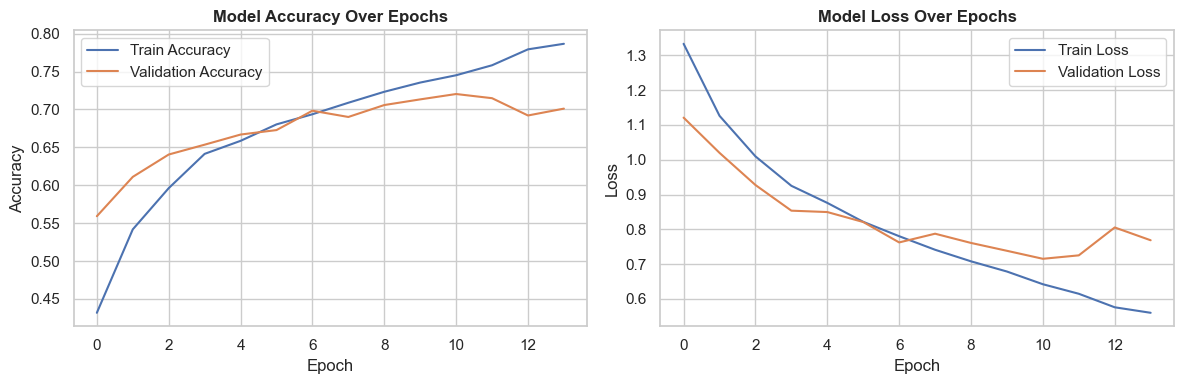

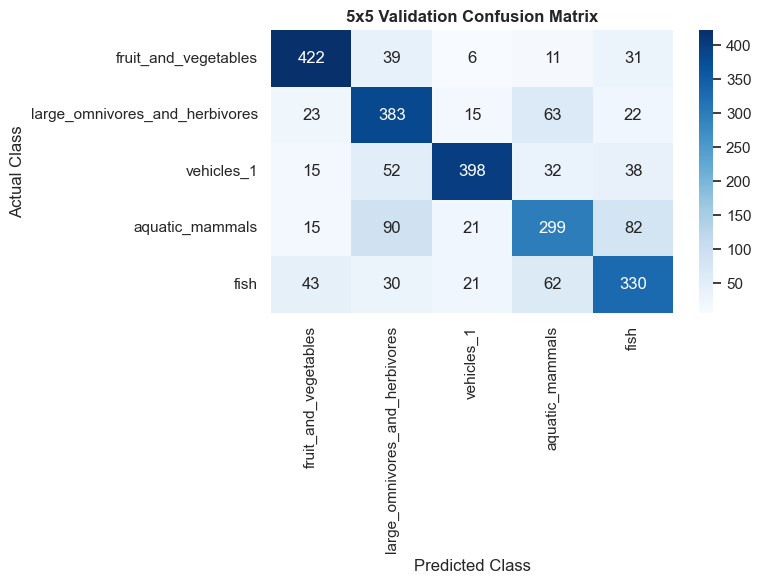

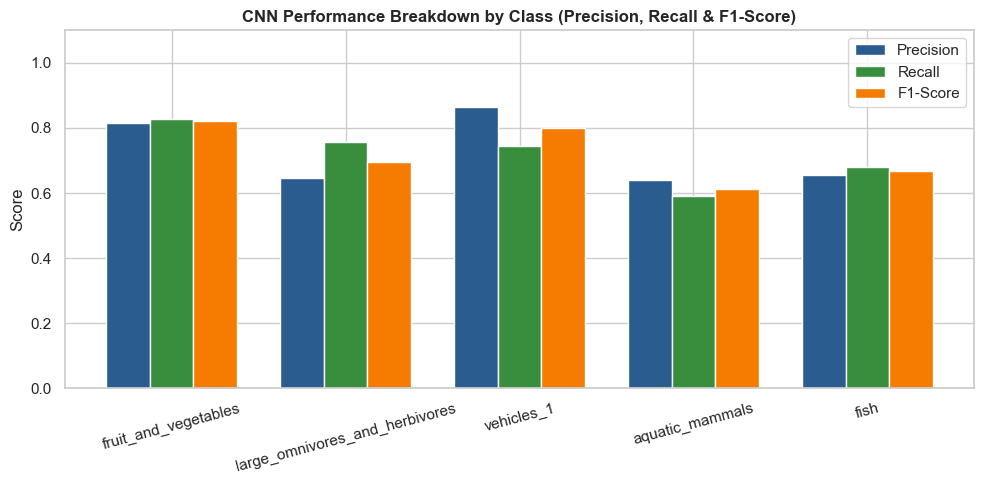

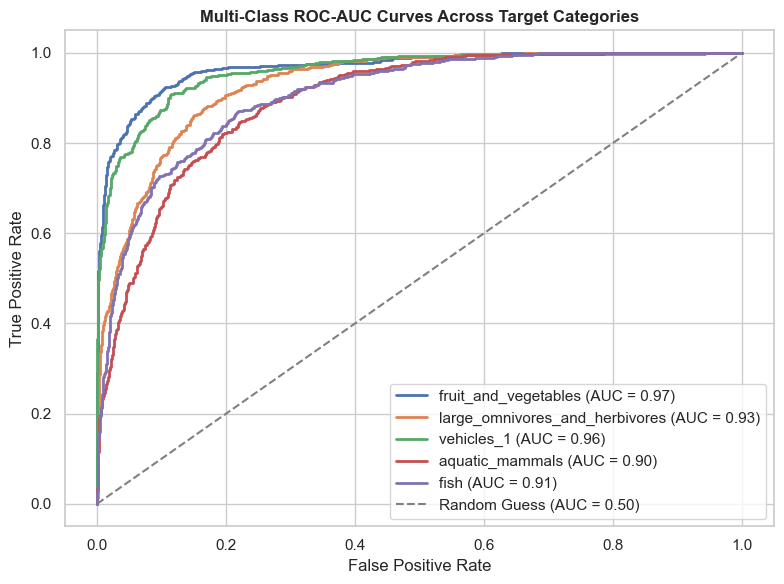

In [21]:
# Model Evaluation & Performance Charts

import time
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc

# Measure single-image prediction speed on the validation dataset
start_time = time.time()
val_probs = cnn_model.predict(X_val)
elapsed = time.time() - start_time
print(f"Inference Speed: {(elapsed / len(X_val)) * 1000:.2f} ms per image")

# Convert predicted probabilities and one-hot ground truth into class IDs (0 to 4)
y_pred = np.argmax(val_probs, axis=1)
y_true = np.argmax(y_val, axis=1)
# Retrieve exact class names matching the StringIndexer mapping
class_names = indexer_model.labels

# Generate and print the 5x5 Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("\n--- 5x5 CONFUSION MATRIX ---")
print(cm)

# Print per-class Precision, Recall, and F1-Scores
print("\n" + "--- CLASSIFICATION REPORT ---".center(75))
print(classification_report(y_true, y_pred, target_names=class_names))


# Compute overall Macro-Averaged ROC-AUC score
macro_auc = roc_auc_score(y_val, val_probs, multi_class="ovr", average="macro")
print(f"Macro-Averaged ROC-AUC Score: {macro_auc:.4f}")

# Plot Training vs. Validation Accuracy and Loss curves side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left chart: Accuracy
axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Model Accuracy Over Epochs", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Right chart: Loss
axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Model Loss Over Epochs", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("eval_accuracy_loss.png", dpi=300)
plt.show()

# Plot the 5x5 Confusion Matrix as a color-coded heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("5x5 Validation Confusion Matrix", fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("eval_confusion_matrix.png", dpi=300)
plt.show()

# Calculate and plot per-class Precision, Recall, and F1-Score bars
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred)
x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, precision, width, label="Precision", color="#2b5c8f")
ax.bar(x, recall, width, label="Recall", color="#388e3c")
ax.bar(x + width, f1, width, label="F1-Score", color="#f57c00")
ax.set_title("CNN Performance Breakdown by Class (Precision, Recall & F1-Score)", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=15)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.legend()
plt.tight_layout()
plt.savefig("eval_per_class_metrics.png", dpi=300)
plt.show()

# Plot One-vs-Rest ROC curves for all 5 classes
plt.figure(figsize=(8, 6))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_val[:, i], val_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.2f})")

# Add diagonal baseline representing random guessing
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Guess (AUC = 0.50)")
plt.title("Multi-Class ROC-AUC Curves Across Target Categories", fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("eval_roc_curves.png", dpi=300)
plt.show()


In [23]:
# Build a tuned CNN with data augmentation and BatchNormalization for retraining
def build_retrained_cnn(input_shape=(32, 32, 3), num_classes=5):
    model = models.Sequential(name="Retrained_Tuned_CNN")
    
    # Apply random horizontal flips and slight rotations to improve generalization
    model.add(layers.RandomFlip("horizontal", input_shape=input_shape))
    model.add(layers.RandomRotation(0.1))
    
    # Block 1 with BatchNormalization to stabilize layer outputs
    model.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.SpatialDropout2D(0.2))
    model.add(layers.MaxPooling2D((2, 2)))
    
    # Block 2 with BatchNormalization
    model.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.SpatialDropout2D(0.2))
    model.add(layers.MaxPooling2D((2, 2)))
    
    # Block 3 with BatchNormalization
    model.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    
    # Dense classification head with stronger 60% Dropout regularization
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(0.6))
    model.add(layers.Dense(num_classes, activation="softmax"))
    
    # Recompile with a lower learning rate (0.0005) for finer weight updates
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Trigger retraining automatically if initial validation accuracy falls below 85%
if max(history.history["val_accuracy"]) < 0.85:
    print("Validation accuracy below 85% threshold. Triggering tuned retraining...")
    retrained_model = build_retrained_cnn()
    retrained_history = retrained_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        callbacks=callbacks
    )
    print(f"Best Retrained Validation Accuracy: {max(retrained_history.history['val_accuracy']):.4f}")


Validation accuracy below 85% threshold. Triggering tuned retraining...


C:\Users\User\anaconda3\lib\site-packages\keras\src\layers\preprocessing\tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 37s 99ms/step - accuracy: 0.3837 - loss: 1.7487 - val_accuracy: 0.2584 - val_loss: 3.3030
Epoch 2/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.5001 - loss: 1.2316 - val_accuracy: 0.5883 - val_loss: 1.0985
Epoch 3/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 29s 94ms/step - accuracy: 0.5256 - loss: 1.1698 - val_accuracy: 0.6496 - val_loss: 0.9240
Epoch 4/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.5612 - loss: 1.1160 - val_accuracy: 0.6359 - val_loss: 0.9301
Epoch 5/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.5853 - loss: 1.0739 - val_accuracy: 0.6516 - val_loss: 0.8752
Epoch 6/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.5957 - loss: 1.0205 - val_accuracy: 0.6732 - val_loss: 0.8309
Epoch 7/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 31s 100ms/step - accuracy: 0.6066 - loss: 1.0103 - val_accuracy: 0.6732 - val_loss: 0.8399
Epoch 8/20
311/311 ━━━━━━━━━━━━━━━━━━━━ 31s 100ms/step - accuracy: 0.6115 - loss: 0.9881 